In [60]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import colormaps as cmaps
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import griddata

# =========================================================
# Read lat/lon from ERA5 reference file
# =========================================================
era5_path = "/work5/ERA5_daily_landgrid_only/global/compressed_sfc_fc_daily_198001.nc4"
ds_era5 = xr.open_dataset(era5_path)
lat_1d = ds_era5["lat"].values
lon_1d = ds_era5["lon"].values

res = 0.25
lon_reg = np.arange(lon_1d.min(), lon_1d.max() + res, res)
lat_reg = np.arange(lat_1d.min(), lat_1d.max() + res, res)
LON, LAT = np.meshgrid(lon_reg, lat_reg)

# ============================================================
#  regrid helper
# ============================================================
def regrid_to_regular(values_1d):
    valid = np.isfinite(lon_1d) & np.isfinite(lat_1d) & np.isfinite(values_1d)
    grid = griddata(
        points=(lon_1d[valid], lat_1d[valid]),
        values=values_1d[valid],
        xi=(LON, LAT),
        method="nearest"
    )
    return grid

# ============================================================
#  plotting helper
# ============================================================
def make_land_mask_from_points(lon_1d, lat_1d, lon_reg, lat_reg):
    land_mask = np.full((len(lat_reg), len(lon_reg)), False, dtype=bool)
    ix = np.round((lon_1d - lon_reg[0]) / (lon_reg[1] - lon_reg[0])).astype(int)
    iy = np.round((lat_1d - lat_reg[0]) / (lat_reg[1] - lat_reg[0])).astype(int)
    valid = (
        (ix >= 0) & (ix < len(lon_reg)) &
        (iy >= 0) & (iy < len(lat_reg)) &
        np.isfinite(lon_1d) & np.isfinite(lat_1d)
    )
    land_mask[iy[valid], ix[valid]] = True
    return land_mask
def make_sig_points_by_fraction(
    lon_1d, lat_1d, p_1d, value_1d,
    threshold=0.05, grid_deg=4.0, frac_thresh=0.3
):
    valid = (
        np.isfinite(lon_1d) & np.isfinite(lat_1d) &
        np.isfinite(p_1d) & np.isfinite(value_1d)
    )
    if np.sum(valid) == 0:
        return np.array([]), np.array([])
    lon_v   = lon_1d[valid]; lat_v = lat_1d[valid]; p_v = p_1d[valid]
    lon_bin = np.floor((lon_v + 180.0) / grid_deg).astype(int)
    lat_bin = np.floor((lat_v +  90.0) / grid_deg).astype(int)
    box_id  = lon_bin.astype(str) + "_" + lat_bin.astype(str)
    keep_lon, keep_lat = [], []
    for box in np.unique(box_id):
        idx      = np.where(box_id == box)[0]
        frac_sig = np.sum(p_v[idx] < threshold) / len(idx)
        if frac_sig >= frac_thresh:
            keep_lon.append((lon_bin[idx[0]] + 0.5) * grid_deg - 180.0)
            keep_lat.append((lat_bin[idx[0]] + 0.5) * grid_deg -  90.0)
    return np.array(keep_lon), np.array(keep_lat)

def filter_sig_points_with_landmask(
    sig_lon, sig_lat, land_mask, lon_reg, lat_reg,
    half_window=2, min_land_frac=0.2
):
    if len(sig_lon) == 0:
        return np.array([]), np.array([])
    ny, nx = land_mask.shape
    keep_lon, keep_lat = [], []
    for x, y in zip(sig_lon, sig_lat):
        ix = np.argmin(np.abs(lon_reg - x))
        iy = np.argmin(np.abs(lat_reg - y))
        x0 = max(ix-2, 0); x1 = min(ix+3, nx)
        y0 = max(iy-2, 0); y1 = min(iy+3, ny)
        if np.mean(land_mask[y0:y1, x0:x1]) >= min_land_frac:
            keep_lon.append(x); keep_lat.append(y)
    return np.array(keep_lon), np.array(keep_lat)

land_mask = make_land_mask_from_points(lon_1d, lat_1d, lon_reg, lat_reg)
def plot_panel(ax, values_1d, sig_lon, sig_lat, title,
               vmin, vmax, cmap, extend="both", label=""):
    plot_grid = values_1d
    im = ax.pcolormesh(
        LON, LAT, plot_grid,
        cmap=cmap,
        transform=ccrs.PlateCarree(),
        vmin=vmin,
        vmax=vmax
    )

    if len(sig_lon) > 0:
        ax.scatter(sig_lon, sig_lat, s=5, c="k",
                   transform=ccrs.PlateCarree(), zorder=5)

    ax.set_extent([-180, 180, -65, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.OCEAN, color="0.9", zorder=1)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, color="black")
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, color="gray")
    ax.coastlines(linewidth=1.5)
    ax.text(
        0.02, 1.05, label,
        transform=ax.transAxes,
        fontsize=30,
        fontweight='bold',
        va='top',
        ha='left'
    )
    # ========================================================
    # inset colorbar
    # ========================================================
    cax = inset_axes(
        ax,
        width="35%",
        height="3%",
        loc='lower center',
        bbox_to_anchor=(0.15, 0.1, 1, 1),
        bbox_transform=ax.transAxes,
        borderpad=0
    )

    cb = plt.colorbar(
        im,
        cax=cax,
        orientation="horizontal",
        extend=extend
    )
    cb.set_ticks([vmin, vmin/2, (vmin+vmax)/2, vmax/2, vmax])
    cb.ax.tick_params(labelsize=16)
    cb.ax.xaxis.set_label_position('top')
    cb.ax.xaxis.set_ticks_position('bottom')
    cb.outline.set_linewidth(1)
    cb.outline.set_edgecolor("black")
    cax.patch.set_alpha(0.8)

    ax.set_title(title, fontsize=20)
    
    # ========================================================
    # inset histogram (area-weighted, same data as map)
    # ========================================================
    lat2d = LAT if np.ndim(LAT) == 2 else np.repeat(LAT[:, None], plot_grid.shape[1], axis=1)
    weights = np.cos(np.deg2rad(lat2d))
    valid_mask = (
        np.isfinite(plot_grid) &
        np.isfinite(weights) &
        land_mask
    )    
    valid_data = plot_grid[valid_mask].ravel()
    valid_weights = weights[valid_mask].ravel()
    
    if len(valid_data) > 0:
        global_mean = np.sum(valid_data * valid_weights) / np.sum(valid_weights)
        global_std = np.sqrt(
            np.sum(valid_weights * (valid_data - global_mean)**2) / np.sum(valid_weights)
        )
    
        # clip only for histogram/colorbar consistency
        hist_data = np.clip(valid_data, vmin, vmax)
        hist_weights = valid_weights / np.sum(valid_weights)
    
        inset_ax = inset_axes(
            ax,
            width="12%",
            height="15%",
            loc="lower left",
            bbox_to_anchor=(0.1, 0.155, 1.1, 1.3),
            bbox_transform=ax.transAxes
        )
    
        bins = np.linspace(vmin, vmax, 22)
    
        hist_vals, bin_edges, patches = inset_ax.hist(
            hist_data,
            bins=bins,
            weights=hist_weights,
            density=False,
            edgecolor="black",
            linewidth=1.2
        )
    
        norm = plt.Normalize(vmin=vmin, vmax=vmax)
        bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    
        for patch, center in zip(patches, bin_centers):
            patch.set_facecolor(cmap(norm(center)))
    
        inset_ax.tick_params(labelsize=14)
        inset_ax.get_yaxis().set_visible(False)

        for spine in inset_ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.2)
            spine.set_color("gray")
            spine.set_alpha(0.5)

        inset_ax.set_xlim(vmin, vmax)
        xticks = np.linspace(vmin, vmax, 3)  # 左、中、右
        inset_ax.set_xticks(xticks)
        formatted_mean = f"{global_mean:.3f}".replace("-", "−")
        formatted_std = f"{global_std:.3f}".replace("-", "−")
        inset_ax.set_facecolor("0.9")
        inset_ax.set_title(
            f"μ = {formatted_mean}\nσ = {formatted_std}",
            fontsize=16,
            ha="left",
            x=0
        )
        xtick_labels = [
            f"<{vmin:.1f}",
            f"{xticks[1]:.1f}",
            f">{vmax:.1f}"
        ]
        inset_ax.set_xticklabels(xtick_labels)
    ax.gridlines(
        draw_labels=False,
        linewidth=0.4,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )

    return im

In [61]:
import os
import numpy as np
import xarray as xr

clim_folder = "/work/home/H.extreme/IPCS_extreme/Plot_main_text_Figure/outcomes"

rad_file = os.path.join(
    clim_folder,
    "thirstwave_metrics_growing_season_new.nc"
)

# ============================================================
# Read NetCDF file
# ============================================================
ds = xr.open_dataset(rad_file)

print(ds)  # Check the variable and dimension names

# Replace "rad_frac_tw" with the actual variable name
rad_frac_tw = ds["rad_frac_tw"]

# Average across the time dimension
rad_frac_tw = rad_frac_tw.mean(dim="year", skipna=True)

# Convert to a float32 NumPy array if required by the function
rad_frac_tw = rad_frac_tw.values.astype(np.float32)
radiation_contribution_1d = rad_frac_tw
# Regrid
rad_frac_tw = regrid_to_regular(rad_frac_tw)

ds.close()

<xarray.Dataset> Size: 197MB
Dimensions:          (year: 43, lgrid: 141780)
Coordinates:
  * year             (year) int64 344B 1981 1982 1983 1984 ... 2021 2022 2023
  * lgrid            (lgrid) int64 1MB 0 1 2 3 4 ... 141776 141777 141778 141779
Data variables:
    intensity        (year, lgrid) float32 24MB ...
    event_count      (year, lgrid) float32 24MB ...
    mean_duration    (year, lgrid) float32 24MB ...
    true_days        (year, lgrid) float32 24MB ...
    gs_days          (year, lgrid) float32 24MB ...
    event_freq_100d  (year, lgrid) float32 24MB ...
    day_fraction     (year, lgrid) float32 24MB ...
    rad_frac_tw      (year, lgrid) float32 24MB ...
    lat              (lgrid) float32 567kB ...
    lon              (lgrid) float32 567kB ...


In [62]:
rad_frac_tw.shape

(556, 1440)

In [63]:
# ============================================================
# Read ERA5 land-grid coordinates
# ============================================================
era5_path = (
    "/work5/ERA5_daily_landgrid_only/"
    "global/compressed_sfc_fc_daily_198001.nc4"
)

with xr.open_dataset(era5_path) as ds_era5:
    lon_1d = ds_era5["lon"].values.astype(np.float64)
    lat_1d = ds_era5["lat"].values.astype(np.float64)

# Regular 0.25° grid
'''
res = 0.25

lon_reg = np.arange(
    lon_1d.min(),
    lon_1d.max() + res / 2,
    res
)

lat_reg = np.arange(
    lat_1d.min(),
    lat_1d.max() + res / 2,
    res
)

LON, LAT = np.meshgrid(lon_reg, lat_reg)
'''
# ============================================================
# Read trend and p value
# ============================================================
clim_folder = (
    "/work/home/H.extreme/IPCS_extreme/"
    "Plot_main_text_Figure/outcomes"
)

trend_file = os.path.join(
    clim_folder,
    "thirstwave_trend_growing_season_new.nc"
)

with xr.open_dataset(trend_file) as ds:
    rad_frac_trend_1d = (
        ds["rad_frac_trend"]
        .values
        .astype(np.float32)
    )

    rad_frac_pvalue_1d = (
        ds["rad_frac_pvalue"]
        .values
        .astype(np.float32)
    )

# Confirm that all arrays use the same lgrid ordering
assert rad_frac_trend_1d.shape == lon_1d.shape, (
    f"Trend shape {rad_frac_trend_1d.shape} does not match "
    f"coordinate shape {lon_1d.shape}"
)

assert rad_frac_pvalue_1d.shape == lon_1d.shape, (
    f"P-value shape {rad_frac_pvalue_1d.shape} does not match "
    f"coordinate shape {lon_1d.shape}"
)

rad_frac_trend = regrid_to_regular(rad_frac_trend_1d)
rad_frac_pvalue = regrid_to_regular(rad_frac_trend_1d)

In [59]:
rad_frac_trend.shape

(556, 1440)

In [29]:
from matplotlib.colors import LinearSegmentedColormap

sunshine_diff_20lev = LinearSegmentedColormap.from_list(
    "sunshine_diff_20lev",
    [
        "#4b1d6b",  # deep purple
        "#6a3d9a",
        "#8c6bb1",
        "#b2abd2",
        "#d8daeb",
        "#efe6b0",  # white center
        "#fee0b6",
        "#fdb863",
        "#e08214",
        "#b35806",
        "#7f3b08",  # deep orange-brown
    ],
    N=20
)
# ============================================================

var_names = ["rad_frac"]

# ============================================================
# Regrid trend and pvalue to regular grid
# ============================================================
trends = {}
pvals = {}

for v in var_names:
    trends[v] = (ds[f"{v}_trend"].values)
    pvals[v]  = (ds[f"{v}_pvalue"].values)
    
sig_lons, sig_lats = {}, {}

for v in var_names:
    slon, slat = make_sig_points_by_fraction(
        lon_1d, lat_1d,
        pvals[v], trends[v],
        threshold=0.05,
        grid_deg=4.0,
        frac_thresh=0.3
    )

    slon, slat = filter_sig_points_with_landmask(
        slon, slat,
        land_mask,
        lon_reg, lat_reg
    )

    sig_lons[v] = slon
    sig_lats[v] = slat

/work/home/H.extreme/miniconda3/envs/TA/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/work/home/H.extreme/miniconda3/envs/TA/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/tmp/ipykernel_2271826/1049027287.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


  ✓ Figure/Figure2.png
  ✓ Figure/Figure2.pdf


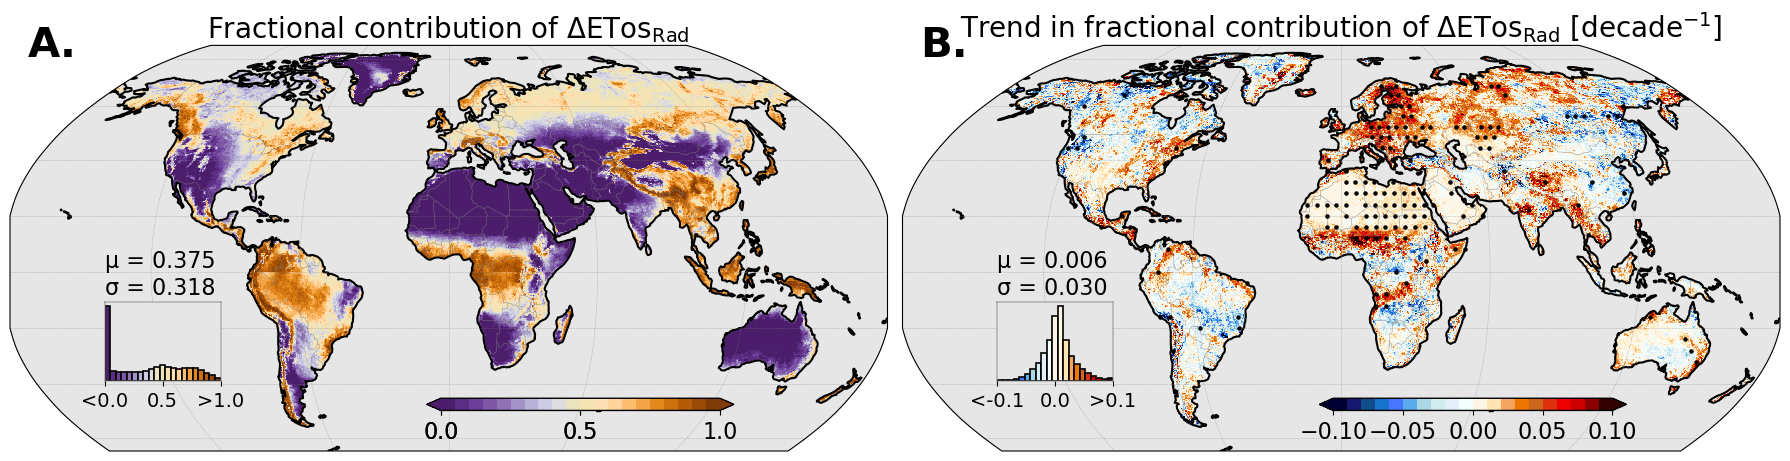

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 25*1/5),
    subplot_kw={"projection": ccrs.Robinson()}
)

axes = axes.flatten()


# panel f) rad - adv term
plot_panel(
    axes[0],
    rad_frac_tw, np.array([]), np.array([]),
    r"Fractional contribution of $\Delta \mathrm{ETos}_{\mathrm{Rad}}$",
    vmin=0, vmax=1,
    cmap=sunshine_diff_20lev,
    extend="both",
    label="A."
)

plot_panel(
    axes[1],
    rad_frac_trend*10,
    sig_lons['rad_frac'], 
    sig_lats['rad_frac'],
    r"Trend in fractional contribution of $\Delta \mathrm{ETos}_{\mathrm{Rad}}$ [decade$^{−1}$]",
    vmin=-0.1, vmax=0.1,
    cmap=cmaps.hotcolr_19lev,
    extend="both",
    label="B."
)


plt.tight_layout()
plt.subplots_adjust(hspace=-0.1)  # negative value pulls rows together

# Save as png and pdf
for ext in ["png", "pdf"]:
        filename = f"Figure/Figure2.{ext}"
        fig.savefig(filename, dpi=300, bbox_inches="tight", pad_inches=0.3)
        print(f"  ✓ {filename}")
    

In [48]:
# ============================================================
# Load and regrid aridity-index percentile for Panel C
# ============================================================
import os
import numpy as np
import xarray as xr
from scipy.interpolate import griddata

ai_file = (
    "/work7/IPCS_extreme/Plot_main_text_Figure/"
    "outcomes/ERA5_aridity_index_percentile_1981_2000.nc"
)

if not os.path.isfile(ai_file):
    raise FileNotFoundError(
        f"Aridity-index file not found:\n{ai_file}"
    )

# ============================================================
# 1. Read the saved land-grid data
# ============================================================
with xr.open_dataset(ai_file) as ds_ai:
    ai_lon_1d = ds_ai["lon"].load().values
    ai_lat_1d = ds_ai["lat"].load().values

    aridity_percentile_1d = (
        ds_ai["aridity_percentile"]
        .load()
        .values
        .astype(np.float32)
    )

print(
    "Number of saved land points:",
    aridity_percentile_1d.size
)


# ============================================================
# 2. Construct the 0.25-degree regular grid
# Use the same grid definition as Panels A/B
# ============================================================
res = 0.25

lon_reg = np.arange(
    ai_lon_1d.min(),
    ai_lon_1d.max() + res / 2,
    res
)

lat_reg = np.arange(
    ai_lat_1d.min(),
    ai_lat_1d.max() + res / 2,
    res
)

LON, LAT = np.meshgrid(
    lon_reg,
    lat_reg
)


# ============================================================
# 3. Regrid helper
# ============================================================
def regrid_to_regular(
    values_1d,
    source_lon,
    source_lat,
    target_lon,
    target_lat
):
    valid = (
        np.isfinite(source_lon) &
        np.isfinite(source_lat) &
        np.isfinite(values_1d)
    )

    if np.sum(valid) == 0:
        return np.full(
            target_lon.shape,
            np.nan,
            dtype=np.float32
        )

    regridded = griddata(
        points=np.column_stack([
            source_lon[valid],
            source_lat[valid]
        ]),
        values=values_1d[valid],
        xi=(target_lon, target_lat),
        method="nearest"
    )

    return regridded.astype(np.float32)


# ============================================================
# 4. Construct land mask from the original land-grid points
# ============================================================
def make_land_mask_from_points(
    source_lon,
    source_lat,
    target_lon_1d,
    target_lat_1d
):
    land_mask = np.zeros(
        (
            target_lat_1d.size,
            target_lon_1d.size
        ),
        dtype=bool
    )

    dlon = target_lon_1d[1] - target_lon_1d[0]
    dlat = target_lat_1d[1] - target_lat_1d[0]

    valid = (
        np.isfinite(source_lon) &
        np.isfinite(source_lat)
    )

    ix = np.rint(
        (
            source_lon[valid] -
            target_lon_1d[0]
        ) / dlon
    ).astype(int)

    iy = np.rint(
        (
            source_lat[valid] -
            target_lat_1d[0]
        ) / dlat
    ).astype(int)

    inside = (
        (ix >= 0) &
        (ix < target_lon_1d.size) &
        (iy >= 0) &
        (iy < target_lat_1d.size)
    )

    land_mask[
        iy[inside],
        ix[inside]
    ] = True

    return land_mask


land_mask = make_land_mask_from_points(
    source_lon=ai_lon_1d,
    source_lat=ai_lat_1d,
    target_lon_1d=lon_reg,
    target_lat_1d=lat_reg
)


# ============================================================
# 5. Regrid aridity percentile and remove ocean values
# ============================================================
aridity_percentile_grid = regrid_to_regular(
    values_1d=aridity_percentile_1d,
    source_lon=ai_lon_1d,
    source_lat=ai_lat_1d,
    target_lon=LON,
    target_lat=LAT
)

# Nearest-neighbour interpolation fills the ocean too.
# Restore ocean grid cells to NaN.
#aridity_percentile_grid[~land_mask] = np.nan

print(
    "Regridded shape:",
    aridity_percentile_grid.shape
)

print(
    "Finite percentile range:",
    np.nanmin(aridity_percentile_grid),
    "to",
    np.nanmax(aridity_percentile_grid)
)

Number of saved land points: 141780
Regridded shape: (555, 1440)
Finite percentile range: 0.00022591687 to 99.99959


In [49]:
# ============================================================
# Panel C map helper
# Same configuration as Panels A/B, but without distribution
# ============================================================
def plot_panel_c(
    ax,
    plot_grid,
    title,
    vmin,
    vmax,
    cmap,
    extend="neither",
    label="C."
):
    cmap_obj = (
        plt.get_cmap(cmap)
        if isinstance(cmap, str)
        else cmap
    )

    im = ax.pcolormesh(
        LON,
        LAT,
        plot_grid,
        cmap=cmap_obj,
        transform=ccrs.PlateCarree(),
        vmin=vmin,
        vmax=vmax,
        shading="auto",
        edgecolors="none",
        linewidth=0,
        antialiased=False,
        rasterized=True
    )

    # Exactly the same geographic extent as Panels A/B
    ax.set_extent(
        [-180, 180, -65, 90],
        crs=ccrs.PlateCarree()
    )

    ax.add_feature(
        cfeature.OCEAN,
        color="0.9",
        zorder=1
    )

    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.6,
        color="black"
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.3,
        color="gray"
    )

    ax.coastlines(
        linewidth=1.5
    )

    ax.gridlines(
        draw_labels=False,
        linewidth=0.4,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )

    # Same panel-label configuration as A/B
    ax.text(
        0.02,
        1.05,
        label,
        transform=ax.transAxes,
        fontsize=30,
        fontweight="bold",
        va="top",
        ha="left"
    )

    ax.set_title(
        title,
        fontsize=20
    )

    # ========================================================
    # Inset colorbar: same configuration as Panels A/B
    # ========================================================
    cax = inset_axes(
        ax,
        width="35%",
        height="3%",
        loc="lower center",
        bbox_to_anchor=(
            0.15,
            0.10,
            1,
            1
        ),
        bbox_transform=ax.transAxes,
        borderpad=0
    )

    cb = plt.colorbar(
        im,
        cax=cax,
        orientation="horizontal",
        extend=extend
    )

    cb.set_ticks(
        [0, 25, 50, 75, 100]
    )

    cb.ax.tick_params(
        labelsize=16
    )

    cb.ax.xaxis.set_label_position(
        "top"
    )

    cb.ax.xaxis.set_ticks_position(
        "bottom"
    )

    cb.outline.set_linewidth(1)
    cb.outline.set_edgecolor("black")

    cax.patch.set_alpha(0.8)

    # No inset histogram/distribution for Panel C

    return im

In [50]:
# ============================================================
# Calculate Panel D statistics by aridity-percentile bins
# ============================================================
def weighted_quantile(values, weights, quantile):
    """Area-weighted quantile."""
    valid = (
        np.isfinite(values) &
        np.isfinite(weights) &
        (weights > 0)
    )

    values = np.asarray(values)[valid]
    weights = np.asarray(weights)[valid]

    if values.size == 0:
        return np.nan

    order = np.argsort(values)
    values = values[order]
    weights = weights[order]

    cumulative_weight = (
        np.cumsum(weights) -
        0.5 * weights
    ) / np.sum(weights)

    return np.interp(
        quantile,
        cumulative_weight,
        values
    )


def summarize_by_aridity_percentile(
    aridity_percentile,
    values,
    latitudes,
    bin_edges
):
    aridity_percentile = np.asarray(
        aridity_percentile
    ).ravel()

    values = np.asarray(values).ravel()
    latitudes = np.asarray(latitudes).ravel()

    weights = np.cos(
        np.deg2rad(latitudes)
    )

    bin_centers = (
        bin_edges[:-1] +
        bin_edges[1:]
    ) / 2

    mean_by_bin = np.full(
        bin_centers.shape,
        np.nan
    )

    q25_by_bin = np.full(
        bin_centers.shape,
        np.nan
    )

    q75_by_bin = np.full(
        bin_centers.shape,
        np.nan
    )

    for i in range(len(bin_centers)):
        # Include 100 in the final bin
        if i == len(bin_centers) - 1:
            in_bin = (
                (aridity_percentile >= bin_edges[i]) &
                (aridity_percentile <= bin_edges[i + 1])
            )
        else:
            in_bin = (
                (aridity_percentile >= bin_edges[i]) &
                (aridity_percentile < bin_edges[i + 1])
            )

        valid = (
            in_bin &
            np.isfinite(aridity_percentile) &
            np.isfinite(values) &
            np.isfinite(weights) &
            (weights > 0)
        )

        if np.any(valid):
            value_valid = values[valid]
            weight_valid = weights[valid]

            mean_by_bin[i] = np.average(
                value_valid,
                weights=weight_valid
            )

            q25_by_bin[i] = weighted_quantile(
                value_valid,
                weight_valid,
                0.25
            )

            q75_by_bin[i] = weighted_quantile(
                value_valid,
                weight_valid,
                0.75
            )

    return (
        bin_centers,
        mean_by_bin,
        q25_by_bin,
        q75_by_bin
    )

# ============================================================
# Aridity-percentile bins
# Here: twenty 5-percentile bins
# ============================================================
ai_bin_edges = np.arange(
    0,
    105,
    5
)


# ============================================================
# Radiation contribution
# Replace radiation_contribution_1d with your variable name
# ============================================================
(
    bin_centers,
    rad_mean_by_ai,
    rad_q25_by_ai,
    rad_q75_by_ai
) = summarize_by_aridity_percentile(
    aridity_percentile=aridity_percentile_1d,
    values=radiation_contribution_1d,
    latitudes=ai_lat_1d,
    bin_edges=ai_bin_edges
)


# ============================================================
# Radiation-contribution trend
# Replace radiation_contribution_trend_1d with your variable name
# ============================================================
(
    bin_centers_trend,
    trend_mean_by_ai,
    trend_q25_by_ai,
    trend_q75_by_ai
) = summarize_by_aridity_percentile(
    aridity_percentile=aridity_percentile_1d,
    values=rad_frac_trend_1d,
    latitudes=ai_lat_1d,
    bin_edges=ai_bin_edges
)

assert np.allclose(
    bin_centers,
    bin_centers_trend
)

/work/home/H.extreme/miniconda3/envs/TA/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/tmp/ipykernel_2271826/2599685313.py:204: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✓ /work7/IPCS_extreme/HH/Figure/Figure2_CD.png
✓ /work7/IPCS_extreme/HH/Figure/Figure2_CD.pdf


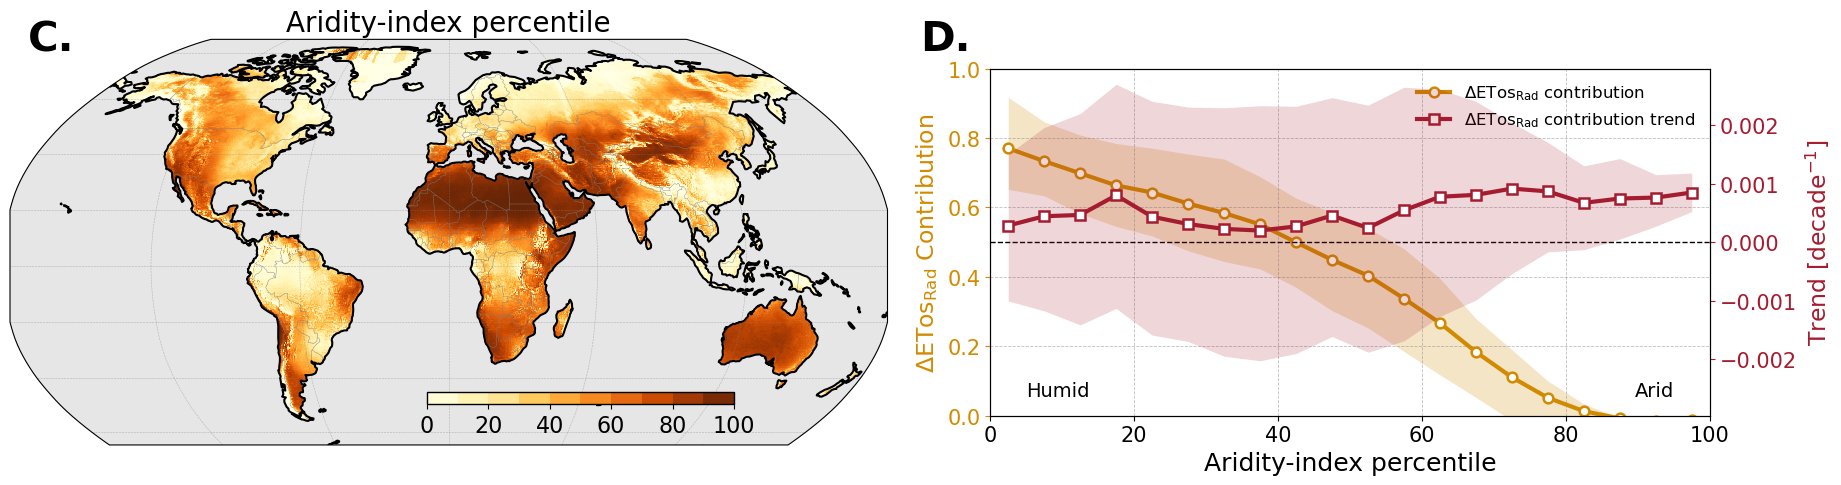

In [69]:
# ============================================================
# 14. Create the same initial geometry used by AB
# ============================================================
from matplotlib.colors import BoundaryNorm

# ============================================================
# Panel C discrete colormap
# One color for every 10 percentiles
# ============================================================
cmap_c = plt.get_cmap(
    "YlOrBr"
).resampled(10)

percentile_boundaries = np.arange(
    0,
    101,
    10
)

norm_c = BoundaryNorm(
    percentile_boundaries,
    ncolors=cmap_c.N,
    clip=True
)

im_c = ax_c.pcolormesh(
    LON,
    LAT,
    aridity_percentile_grid,
    cmap=cmap_c,
    norm=norm_c,
    transform=ccrs.PlateCarree(),
    shading="auto",
    edgecolors="none",
    linewidth=0,
    antialiased=False,
    rasterized=True,
    zorder=0
)

fig, reference_axes = plt.subplots(
    1,
    2,
    figsize=(18, 25 * 1/5),
    subplot_kw={
        "projection": ccrs.Robinson()
    }
)

reference_axes = reference_axes.flatten()

ax_c = reference_axes[0]
ax_d_placeholder = reference_axes[1]


# ============================================================
# 15. Draw Panel C
# Same configuration as Panels A and B
# No inset distribution
# ============================================================
cmap_c = plt.get_cmap("YlOrBr")

im_c = ax_c.pcolormesh(
    LON,
    LAT,
    aridity_percentile_grid,
    cmap=cmap_c,
    transform=ccrs.PlateCarree(),
    shading="auto",

    # Remove white rendering gaps
    edgecolors="none",
    linewidth=0,
    antialiased=False,
    rasterized=True,

    zorder=0
)

ax_c.set_extent(
    [-180, 180, -65, 90],
    crs=ccrs.PlateCarree()
)

ax_c.add_feature(
    cfeature.OCEAN,
    color="0.9",
    zorder=1
)

ax_c.add_feature(
    cfeature.COASTLINE,
    linewidth=0.6,
    color="black",
    zorder=2
)

ax_c.add_feature(
    cfeature.BORDERS,
    linewidth=0.3,
    color="gray",
    zorder=2
)

ax_c.coastlines(
    linewidth=1.5,
    zorder=3
)

ax_c.gridlines(
    draw_labels=False,
    linewidth=0.4,
    color="gray",
    alpha=0.5,
    linestyle="--",
    zorder=4
)

ax_c.text(
    0.02,
    1.05,
    "C.",
    transform=ax_c.transAxes,
    fontsize=30,
    fontweight="bold",
    va="top",
    ha="left"
)

ax_c.set_title(
    "Aridity-index percentile",
    fontsize=20
)


# ============================================================
# 16. Panel C inset colorbar
# No distribution histogram
# ============================================================
cax_c = inset_axes(
    ax_c,
    width="35%",
    height="3%",
    loc="lower center",
    bbox_to_anchor=(
        0.15,
        0.10,
        1,
        1
    ),
    bbox_transform=ax_c.transAxes,
    borderpad=0
)

cb_c = plt.colorbar(
    im_c,
    cax=cax_c,
    orientation="horizontal",
    boundaries=percentile_boundaries,
    ticks=np.arange(0, 101, 20),
    spacing="uniform",
    extend="neither"
)

cb_c.ax.tick_params(
    labelsize=14
)

cb_c.ax.xaxis.set_ticks_position(
    "bottom"
)

cb_c.outline.set_linewidth(1)
cb_c.outline.set_edgecolor("black")

cax_c.patch.set_alpha(0.8)

cb_c.ax.tick_params(
    labelsize=16
)

cb_c.ax.xaxis.set_label_position(
    "top"
)

cb_c.ax.xaxis.set_ticks_position(
    "bottom"
)

cb_c.outline.set_linewidth(1)
cb_c.outline.set_edgecolor("black")

cax_c.patch.set_alpha(0.8)


# ============================================================
# 17. Establish the AB geometry
# ============================================================
ax_d_placeholder.set_title(
    " ",
    fontsize=20
)

plt.tight_layout()

plt.subplots_adjust(
    hspace=-0.1
)

fig.canvas.draw()

c_slot = ax_c.get_position().frozen()
d_slot = ax_d_placeholder.get_position().frozen()
# Original right-hand panel slot corresponding to Panel B
d_slot = (
    ax_d_placeholder
    .get_position()
    .frozen()
)

# Fix the D label at the original slot position.
# It will not move when the plot itself is reduced.
d_label_x = (
    d_slot.x0 +
    0.02 * d_slot.width
)

# Use Panel C's actual vertical position
d_label_y = (
    c_slot.y0 +
    1.05 * c_slot.height
)
# Remove temporary Robinson axis
ax_d_placeholder.remove()


# ============================================================
# 18. Reduce the Panel D plotting area
# ============================================================
# Adjust these values if slightly more/less reduction is desired
d_width_fraction = 0.82
d_height_fraction = 0.78

# Move the plotting area slightly to the right,
# providing more space between C and D's left ylabel.
d_left_padding = 0.10 * d_slot.width

# Vertically center the reduced Panel D
d_bottom_padding = (
    0.5 *
    (1.0 - d_height_fraction) *
    d_slot.height
)

d_plot_position = [
    d_slot.x0 + d_left_padding,
    d_slot.y0 + d_bottom_padding,
    d_slot.width * d_width_fraction,
    d_slot.height * d_height_fraction
]

ax_d = fig.add_axes(
    d_plot_position
)


# ============================================================
# 19. Draw Panel D
# ============================================================
rad_color = "#D28A00"
trend_color = "#A51C30"


# ------------------------------------------------------------
# Left y-axis: radiation contribution
# ------------------------------------------------------------
ax_d.fill_between(
    bin_centers,
    rad_q25_by_ai,
    rad_q75_by_ai,
    color=rad_color,
    alpha=0.22,
    linewidth=0,
    zorder=1
)

line_rad, = ax_d.plot(
    bin_centers,
    rad_mean_by_ai,
    color=rad_color,
    linewidth=3,
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor=rad_color,
    markeredgewidth=1.8,
    label="Radiation contribution",
    zorder=3
)

ax_d.set_xlim(
    0,
    100
)

ax_d.set_ylim(
    0,
    1
)

ax_d.set_xticks(
    np.arange(0, 101, 20)
)

ax_d.set_xlabel(
    "Aridity-index percentile",
    fontsize=18
)

ax_d.set_ylabel(
    r"$\Delta \mathrm{ETos}_{\mathrm{Rad}}$ Contribution",
    fontsize=17,
    color=rad_color,
    labelpad=5
)

ax_d.tick_params(
    axis="x",
    labelsize=15
)

ax_d.tick_params(
    axis="y",
    labelsize=15,
    colors=rad_color
)

ax_d.grid(
    linewidth=0.6,
    color="gray",
    alpha=0.5,
    linestyle="--"
)


# ------------------------------------------------------------
# Right y-axis: radiation-contribution trend
# ------------------------------------------------------------
ax_d_right = ax_d.twinx()

ax_d_right.fill_between(
    bin_centers,
    trend_q25_by_ai,
    trend_q75_by_ai,
    color=trend_color,
    alpha=0.18,
    linewidth=0,
    zorder=1
)

line_trend, = ax_d_right.plot(
    bin_centers,
    trend_mean_by_ai,
    color=trend_color,
    linewidth=3,
    marker="s",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor=trend_color,
    markeredgewidth=1.8,
    label="Radiation-contribution trend",
    zorder=3
)

ax_d_right.axhline(
    0,
    color="black",
    linewidth=1,
    linestyle="--",
    zorder=0
)

ax_d_right.set_ylabel(
    r"Trend [decade$^{-1}$]",
    fontsize=17,
    color=trend_color,
    labelpad=5
)

ax_d_right.tick_params(
    axis="y",
    labelsize=15,
    colors=trend_color
)


# ============================================================
# 20. Symmetric right-axis range
# ============================================================
trend_spread = np.concatenate([
    trend_q25_by_ai[
        np.isfinite(trend_q25_by_ai)
    ],
    trend_q75_by_ai[
        np.isfinite(trend_q75_by_ai)
    ]
])

if trend_spread.size > 0:
    trend_limit = np.nanmax(
        np.abs(trend_spread)
    )

    if (
        np.isfinite(trend_limit) and
        trend_limit > 0
    ):
        ax_d_right.set_ylim(
            -1.1 * trend_limit,
            1.1 * trend_limit
        )


# ============================================================
# 21. Panel D annotations
# ============================================================
ax_d.set_title("")

# Fixed D label in figure coordinates.
# It is based on the original B slot and does not move
# when ax_d is reduced.
fig.text(
    d_label_x,
    d_label_y,
    "D.",
    fontsize=30,
    fontweight="bold",
    va="top",
    ha="left"
)

ax_d.text(
    5,
    0.1,
    "Humid",
    transform=ax_d.get_xaxis_transform(),
    fontsize=14,
    ha="left",
    va="top"
)

ax_d.text(
    95,
    0.1,
    "Arid",
    transform=ax_d.get_xaxis_transform(),
    fontsize=14,
    ha="right",
    va="top"
)

ax_d.legend(
    handles=[
        line_rad,
        line_trend
    ],
    labels=[
        r"$\Delta \mathrm{ETos}_{\mathrm{Rad}}$ contribution",
        r"$\Delta \mathrm{ETos}_{\mathrm{Rad}}$ contribution trend"
    ],
    loc="upper right",
    fontsize=12,
    frameon=False
)
'''
ax_d.text(
    0.98,
    0.03,
    "Shading: area-weighted spatial IQR",
    transform=ax_d.transAxes,
    fontsize=11,
    color="0.3",
    ha="right",
    va="bottom"
)

'''
# ============================================================
# 22. Save
# Do not use tight_layout after this point
# ============================================================

outdir = (
    "/work7/IPCS_extreme/"
    "HH/Figure"
)
for ext in ["png", "pdf"]:
    filename = os.path.join(
        outdir,
        f"Figure2_CD.{ext}"
    )

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.3
    )

    print(f"✓ {filename}")


plt.show()

AB size: (5490, 1498)
CD size: (5638, 1576)
✓ /work7/IPCS_extreme/HH/Figure/Figure2_combined.png
✓ /work7/IPCS_extreme/HH/Figure/Figure2_combined.pdf


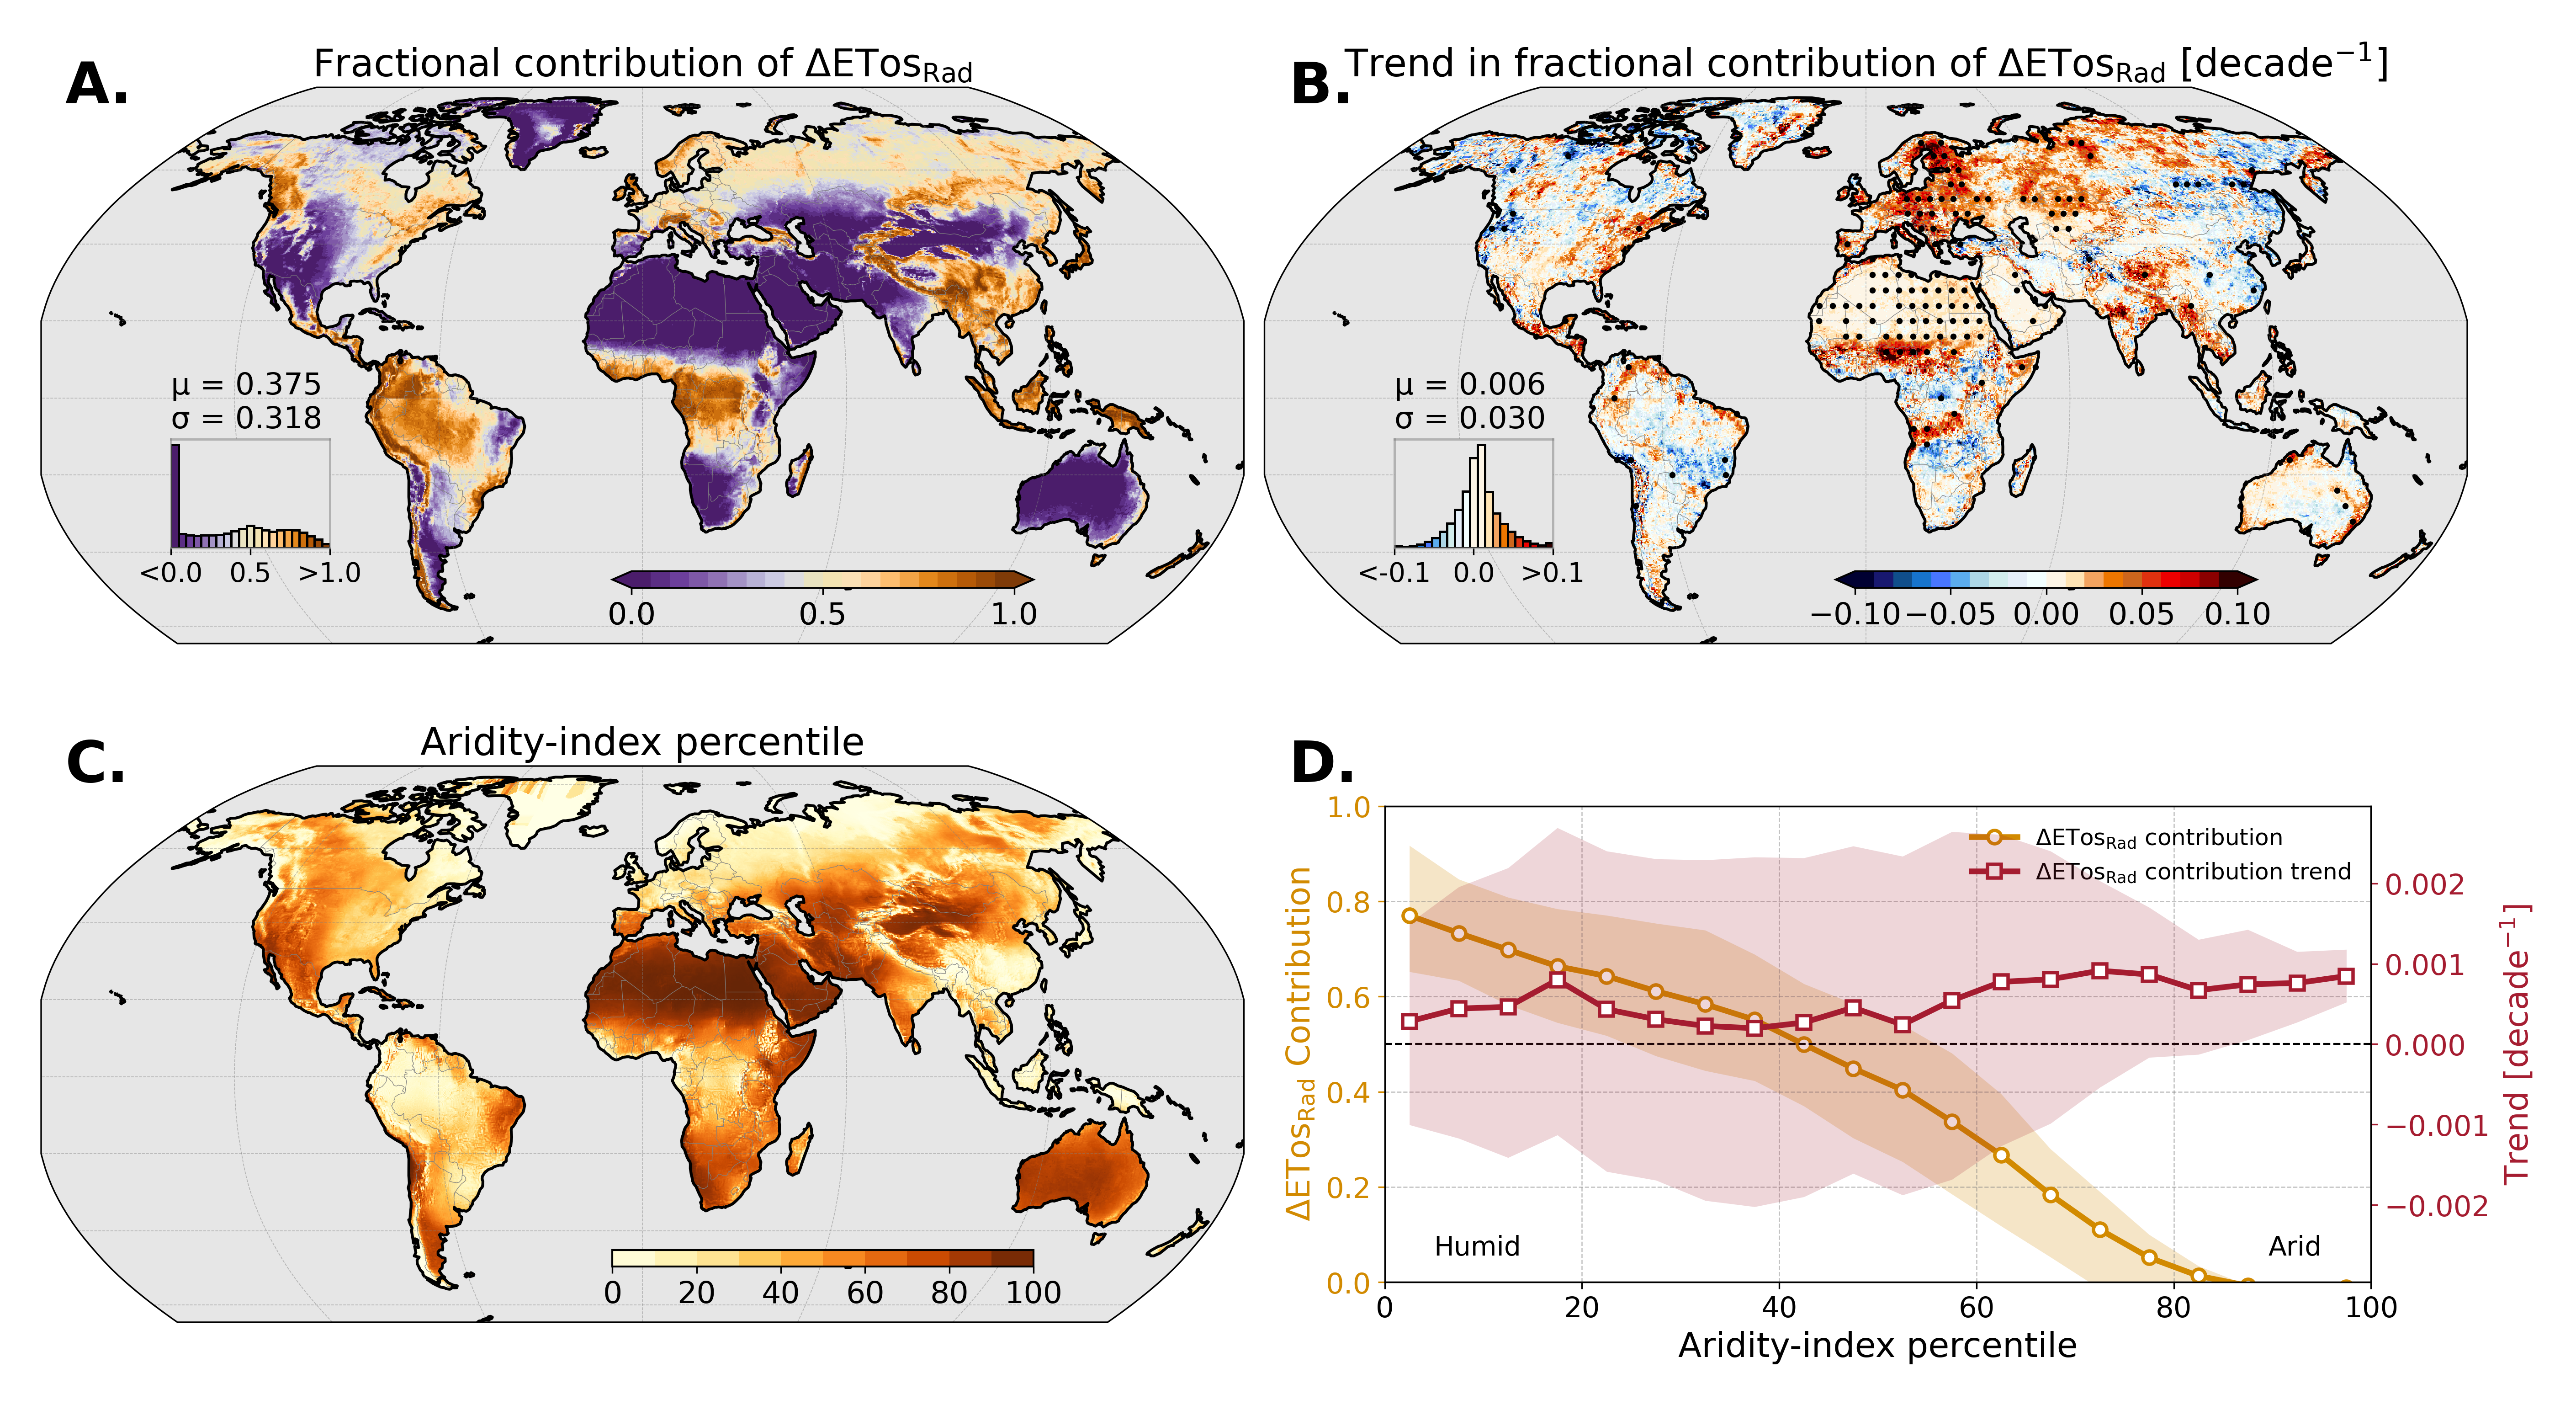

In [70]:
# ============================================================
# Combine the original AB and CD figures without resizing
# This preserves all previously adjusted panel geometry
# ============================================================
from PIL import Image
import os

figure_dir = "/work7/IPCS_extreme/HH/Figure"

ab_file = os.path.join(
    figure_dir,
    "Figure2.png"
)

cd_file = os.path.join(
    figure_dir,
    "Figure2_CD.png"
)

# ============================================================
# Read original figures
# ============================================================
img_ab = Image.open(ab_file).convert("RGB")
img_cd = Image.open(cd_file).convert("RGB")

print("AB size:", img_ab.size)
print("CD size:", img_cd.size)


# ============================================================
# Do not resize either image
# Use a common canvas and preserve original proportions
# ============================================================
combined_width = max(
    img_ab.width,
    img_cd.width
)

combined_height = (
    img_ab.height +
    img_cd.height
)

combined = Image.new(
    mode="RGB",
    size=(
        combined_width,
        combined_height
    ),
    color="white"
)


# ============================================================
# Left-align both rows
# This preserves the A–C and B–D column positions
# ============================================================
combined.paste(
    img_ab,
    (0, 0)
)

combined.paste(
    img_cd,
    (0, img_ab.height)
)


# ============================================================
# Save complete 2 × 2 figure
# ============================================================
png_file = os.path.join(
    figure_dir,
    "Figure2_combined.png"
)

pdf_file = os.path.join(
    figure_dir,
    "Figure2_combined.pdf"
)

combined.save(
    png_file,
    dpi=(300, 300)
)

combined.save(
    pdf_file,
    resolution=300
)

print(f"✓ {png_file}")
print(f"✓ {pdf_file}")


# ============================================================
# Preview
# ============================================================
display(combined)